In [66]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [67]:
df = pd.read_csv("bank-full.csv", sep=";")

In [68]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [69]:
df.shape

(45211, 17)

In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [71]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [72]:
df.duplicated().sum()

0

In [73]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [74]:
df.describe(include='object')

,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922


In [75]:
mean = df['age'].mean()
median = df['age'].median()
mode = df['age'].mode()

print("Mean:", mean)
print("Median:", median)
print("Mode:", mode)

Mean: 40.93621021432837
Median: 39.0
Mode: 0    32
Name: age, dtype: int64


In [76]:
# Measures of Dispersion

age_range = df['age'].max() - df['age'].min()
variance = df['age'].var()
std = df['age'].std()

print("Range:", age_range)
print("Variance:", variance)
print("Standard Deviation:", std)

Range: 77
Variance: 112.75810728286069
Standard Deviation: 10.618762040975431


In [77]:
Q1 = df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 33.0
Q3: 48.0
IQR: 15.0


### Age Distribution

I selected the age column to understand the age distribution of bank customers. I calculated the mean, median and standard deviation to understand the data. I used a histogram to see which age groups are most common and a boxplot to identify possible outliers.

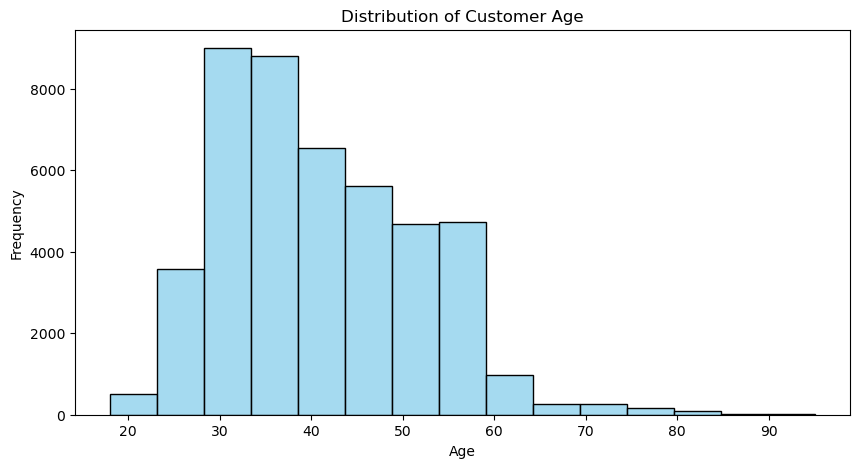

In [78]:
plt.figure(figsize=(10, 5))
sns.histplot(df['age'], bins=15, color='skyblue')

plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

In [79]:
# Skewness of Customer Age
df['age'].skew()

0.6848179257252598

Histogram shows most customers are approximately between 28-60 years old. the distribution is positively skewed and few customers are older age groups.The mean age 40.94 is slightly higher than the median 39, which is consistent with the positive skewness 0.685 observed in the age distribution.

### Age Boxplot

A boxplot was used to examine the median, quartiles, and potential outliers in customer ages.

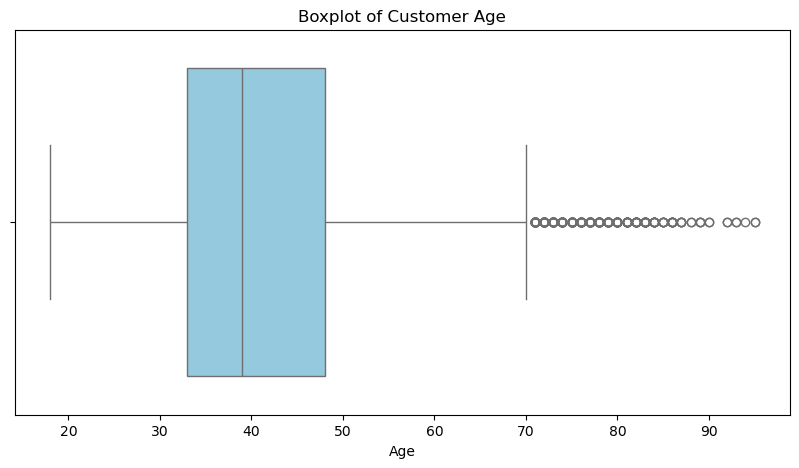

In [80]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['age'], color='skyblue')

plt.title('Boxplot of Customer Age')
plt.xlabel('Age')
plt.show()

The boxplot shows that 50% of customers are between 33 and 48 years old. The median age is 39. There are also some outliers above 70 years old. This means that some customers are much older than most others. The result is similar to the histogram, where most customers are in the younger and middle-aged groups.

### Balance Distribution


Customer balance was selected to examine how account balances vary between customers. Descriptive statistics were calculated to understand the average balance and the variation in the data. The IQR method was also used to identify possible outliers.

In [81]:
# Descriptive Statistics of Balance

print("Mean:", df['balance'].mean())
print("Median:", df['balance'].median())
print("Standard Deviation:", df['balance'].std())

Mean: 1362.2720576850766
Median: 448.0
Standard Deviation: 3044.7658291686002


In [82]:
# Detect outliers in balance

Q1 = df['balance'].quantile(0.25)
Q3 = df['balance'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower bound:", lower)
print("Upper bound:", upper)

Lower bound: -1962.0
Upper bound: 3462.0


In [83]:
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 72.0
Q3: 1428.0
IQR: 1356.0


In [84]:
outliers = df[(df['balance'] < lower) |
              (df['balance'] > upper)]

print("Number of outliers:", len(outliers))

Number of outliers: 4729


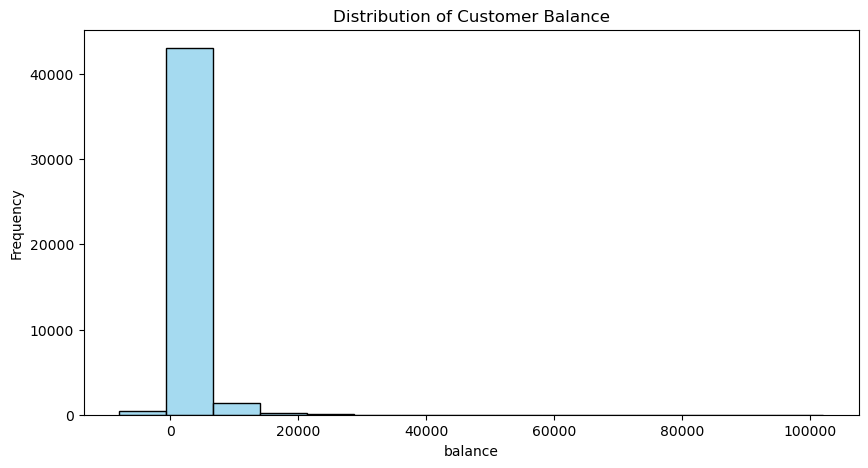

In [85]:
plt.figure(figsize=(10, 5))
sns.histplot(df['balance'], bins=15, color='skyblue')

plt.title('Distribution of Customer Balance')
plt.xlabel('balance')
plt.ylabel('Frequency')
plt.show()

In [86]:
# Skewness of Customer Balance
df['balance'].skew()

8.360308326166326

The histogram shows that most customers have low account balances, while a few have very high balances. The distribution is strongly right-skewed skewness = 8.36. The mean balance is 1,362.27, which is much higher than the median of 448. This suggests that a small number of high balances increase the average.

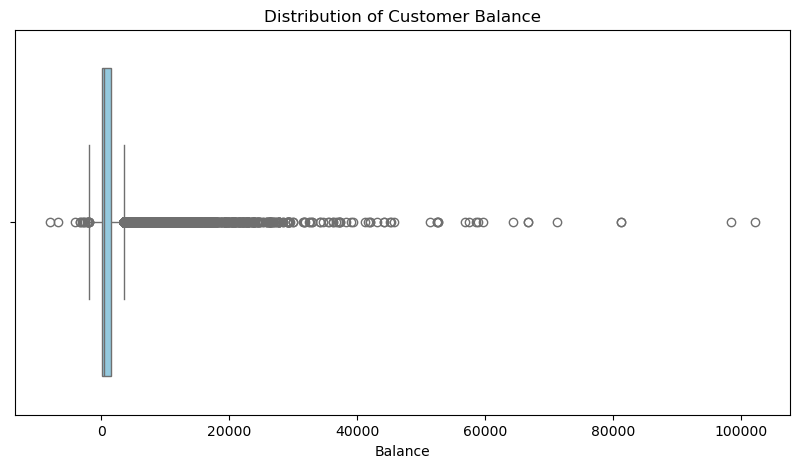

In [87]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['balance'], color='skyblue')
plt.title('Distribution of Customer Balance')
plt.xlabel('Balance')
plt.show()

The boxplot shows that most account balances are concentrated at lower values. The median balance is 448, and the middle 50% of balances are between 72 and 1,428. Using the IQR method, 4,729 outliers (10.46%) were identified. These values are below -1,962 or above 3,462. This shows that some customers have very different balances compared to others.